# Case Study 1: Analysis and Clustering of Online Retail Transactions

**Subject:** Fundamentals of Data Science  |  **Student:** Marru Mahathi Rao  |  **Roll No:** 160124733150

**Dataset:** `Online retail_new.csv` - 7,501 shopping baskets, each listing up to 20 products purchased together.

## 1. Problem statement and objectives

An online retail store has transaction records in which several products are bought together, but it has no systematic analysis of what its baskets look like or which baskets are similar. The goal is to analyse the transactions with statistical and machine-learning methods, find groups of similar baskets, compare clustering algorithms, and draw business conclusions.

**Objectives (from the case study)**
1. Understand the structure of the dataset.
2. Clean and pre-process the transaction records with Pandas.
3. Compute descriptive statistics and identify frequently occurring products.
4. Visualise product frequencies and transaction-size distributions.
5. Represent transactions as numerical feature vectors.
6. Apply PCA for dimensionality reduction and visualisation.
7. Implement K-means, hierarchical, DBSCAN and spectral clustering.
8. Compare the algorithms with the silhouette coefficient and the Davies-Bouldin index.
9. Discuss limitations and business implications.

## 2. Methodology overview

1. Load and inspect the data (a file **without a header row**, so `header=None` is essential).
2. Clean: strip spaces, lower-case names, replace blanks by missing values, convert each row to a basket (list of products).
3. Descriptive statistics and visualisation of basket sizes and product frequencies.
4. One-hot encode baskets into a 7,501 x 119 binary matrix (1 = product is in the basket).
5. PCA for visualisation and to see how much structure a few dimensions capture.
6. Choose the number of clusters for K-means with the elbow, silhouette and Davies-Bouldin curves, then run the four algorithms.
7. Compare all algorithms **fairly on the same sample of transactions and with the same scoring metric**, and profile the resulting clusters.

## 3. Statistical findings: data, cleaning and descriptive statistics

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

### Objective 1: Understand the structure of the dataset
The file has no header row, so I read it with `header=None`; otherwise pandas would treat the first basket as column names and silently lose a transaction.

In [2]:
retail = pd.read_csv("Online retail_new.csv", header=None)

print("Shape (rows x columns):", retail.shape)
print("First 5 baskets (showing the first 10 of the 20 slot columns):")
display(retail.iloc[:, :10].head())
print("Total empty cells:", int(retail.isna().sum().sum()), "out of", retail.size)

Shape (rows x columns): (7501, 20)
First 5 baskets (showing the first 10 of the 20 slot columns):


,0,1,2,3,4,5,6,7,8,9
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN


Total empty cells: 120657 out of 150020


**Observation.** There are **7,501 transactions** and 20 columns. The columns are not features: each one is just a *slot* in the basket (the first product, the second product, and so on). Empty cells (`NaN`) mean "no product in this slot", and they make up about 80% of the table because most baskets contain far fewer than 20 items.

### Objective 2: Clean and pre-process with Pandas

In [3]:
# Strip spaces / lower-case product names so that " asparagus" and "asparagus" are the same product.
# (astype("string") works for every pandas version; checking dtype == "object" would silently skip the clean-up in newer pandas.)
retail = retail.apply(lambda col: col.astype("string").str.strip().str.lower())
retail = retail.replace(r"^\s*$", pd.NA, regex=True)

# Convert each row to a basket (list of distinct products); drop empty slots
transactions = [list(dict.fromkeys(row.dropna().tolist())) for _, row in retail.iterrows()]
n_repeated = int(sum(len(set(r.dropna())) != r.notna().sum() for _, r in retail.iterrows()))

basket_sizes = pd.Series([len(t) for t in transactions], name="basket_size")
all_items = pd.Series([item for t in transactions for item in t])

print("Transactions:", len(transactions))
print("Empty baskets:", int((basket_sizes == 0).sum()))
print("Baskets where the same product was listed twice (kept once):", n_repeated)
print("Unique products:", all_items.nunique())
print("Duplicate baskets (identical sets of products):", len(transactions) - len({frozenset(t) for t in transactions}))

Transactions: 7501
Empty baskets: 0
Baskets where the same product was listed twice (kept once): 5
Unique products: 119
Duplicate baskets (identical sets of products): 2347


**Observation and decisions.**
- After normalising names there are **no empty baskets** and no product listed twice in one basket.
- There are many **duplicate baskets** (for example many customers who bought only "mineral water"). I **keep them**: two different customers can legitimately buy the same items, and removing them would distort frequencies and cluster sizes.
- The cleaned data has the number of unique products shown above.

### Objective 3: Descriptive statistics and frequent products

In [4]:
print("Basket size statistics (number of products per transaction):")
display(basket_sizes.describe().round(2).to_frame().T)
print("Skewness:", round(basket_sizes.skew(), 2), "| Mode:", basket_sizes.mode().iloc[0])

product_counts = all_items.value_counts()
support = (product_counts / len(transactions) * 100).round(2)   # % of baskets containing the product
top15 = pd.DataFrame({"Count": product_counts, "Support (% of baskets)": support}).head(15)
display(top15)

print("\nProducts that appear in fewer than 1% of baskets:", int((support < 1).sum()), "of", len(support))
print("Share of all purchases made by the top 10 products:", round(product_counts.head(10).sum() / product_counts.sum() * 100, 1), "%")

Basket size statistics (number of products per transaction):


,count,mean,std,min,25%,50%,75%,max
basket_size,7501.0,3.91,2.9,1.0,2.0,3.0,5.0,20.0


Skewness: 1.19 | Mode: 1


,Count,Support (% of baskets)
mineral water,1788,23.84
eggs,1348,17.97
spaghetti,1306,17.41
french fries,1282,17.09
chocolate,1229,16.38
green tea,991,13.21
milk,972,12.96
ground beef,737,9.83
frozen vegetables,715,9.53
pancakes,713,9.51



Products that appear in fewer than 1% of baskets: 44 of 119
Share of all purchases made by the top 10 products: 37.7 %


**Interpretation.**
- The dataset has **7,501 transactions and 119 unique products** (after removing a leading space that made " asparagus" and "asparagus" look like two different products).
- Baskets are small: mean **3.91** products, median **3**, most common size **1**, maximum 20. The mean is above the median and the skewness is **1.19**, so the distribution is **right-skewed**: most customers buy a few items, a few buy very large baskets.
- **Mineral water** is the most frequent product (in 23.8% of baskets), followed by eggs (18.0%), spaghetti (17.4%), french fries (17.1%) and chocolate (16.4%). The top 10 products make up **37.7%** of all items sold, while **44 of the 119 products appear in under 1% of baskets**, a long-tail pattern typical of retail.
- About 2,347 baskets (31%) are exact duplicates of another basket; I keep them because they represent real purchases.

### Objective 4: Visualise product frequencies and transaction sizes

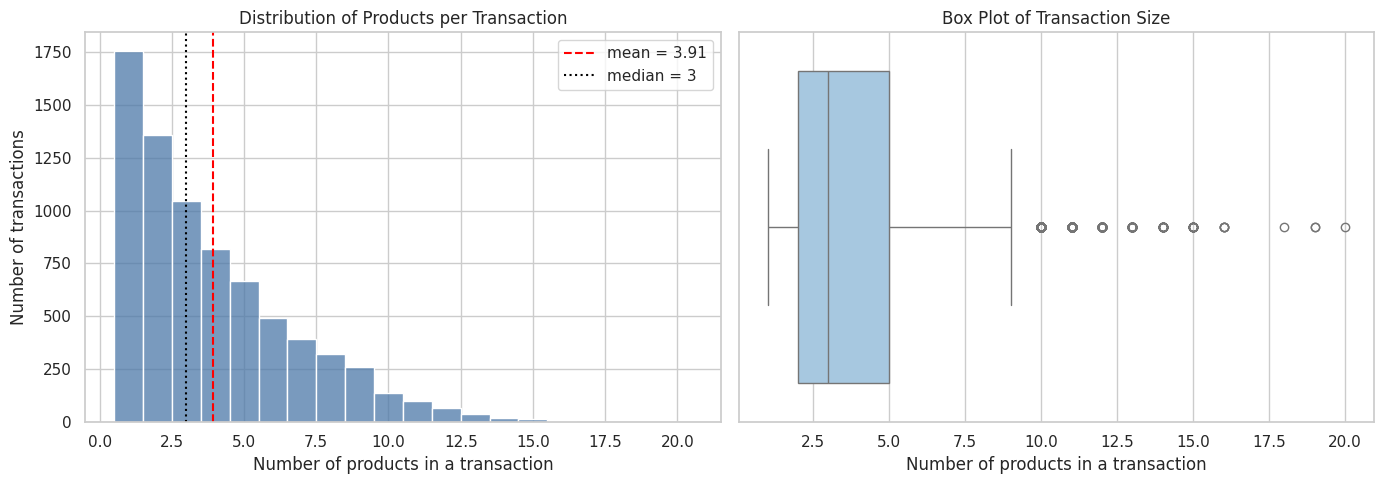

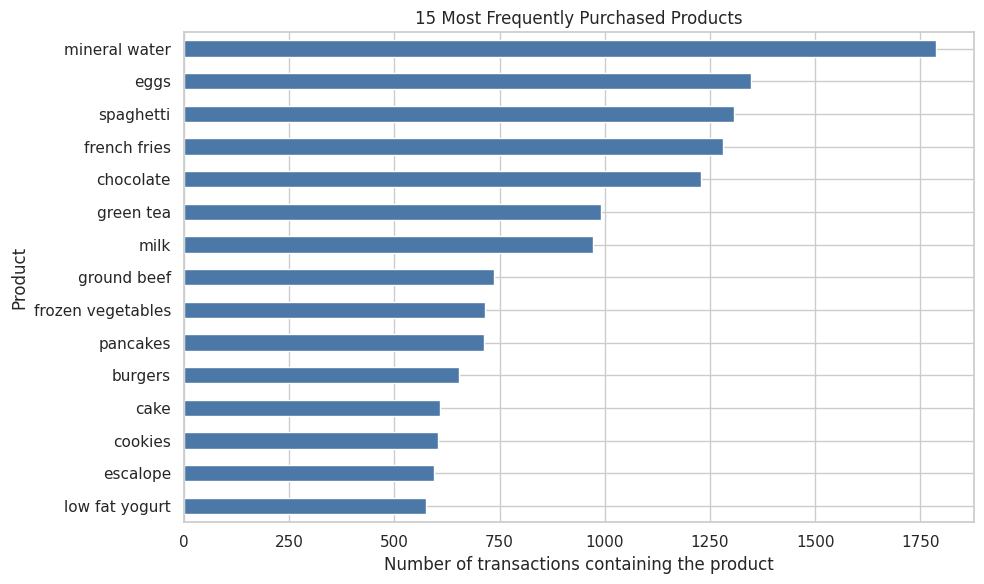

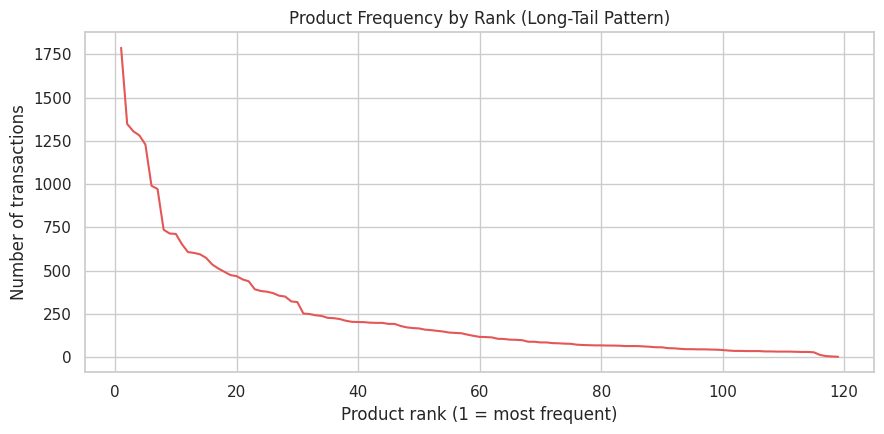

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(basket_sizes, discrete=True, ax=axes[0], color="#4c78a8")
axes[0].axvline(basket_sizes.mean(), color="red", linestyle="--", label=f"mean = {basket_sizes.mean():.2f}")
axes[0].axvline(basket_sizes.median(), color="black", linestyle=":", label=f"median = {basket_sizes.median():.0f}")
axes[0].set_title("Distribution of Products per Transaction")
axes[0].set_xlabel("Number of products in a transaction")
axes[0].set_ylabel("Number of transactions")
axes[0].legend()

sns.boxplot(x=basket_sizes, ax=axes[1], color="#9ecae9")
axes[1].set_title("Box Plot of Transaction Size")
axes[1].set_xlabel("Number of products in a transaction")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
top15["Count"].sort_values().plot(kind="barh", color="#4c78a8")
plt.title("15 Most Frequently Purchased Products")
plt.xlabel("Number of transactions containing the product")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(product_counts) + 1), product_counts.values, color="#e45756")
plt.title("Product Frequency by Rank (Long-Tail Pattern)")
plt.xlabel("Product rank (1 = most frequent)")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

**Interpretation of the plots.**
- **Transaction size:** the histogram is clearly right-skewed with a peak at 1-3 items, and the box plot shows baskets of about 10 or more items as outliers. The business is therefore dominated by small baskets.
- **Top products:** the bar chart shows that a handful of staples (mineral water, eggs, spaghetti, french fries, chocolate) appear far more often than the rest.
- **Long tail:** the rank-frequency curve falls steeply and then flattens. This matters for clustering, because most products occur in very few baskets, so most baskets share very few products with each other.

## 4. Feature representation (Objective 5)

In [6]:
mlb = MultiLabelBinarizer()
X_df = pd.DataFrame(mlb.fit_transform(transactions), columns=mlb.classes_)
X = X_df.values.astype(float)

print("Feature matrix shape (transactions x products):", X_df.shape)
print("Sparsity (share of zeros):", round((X == 0).mean() * 100, 1), "%")
print("Row sums equal basket sizes:", bool((X.sum(axis=1) == basket_sizes.values).all()))
print("First 5 baskets as binary vectors (first 8 of the 119 product columns shown):")
display(X_df.iloc[:, :8].head())

Feature matrix shape (transactions x products): (7501, 119)
Sparsity (share of zeros): 96.7 %
Row sums equal basket sizes: True
First 5 baskets as binary vectors (first 8 of the 119 product columns shown):


,almonds,antioxydant juice,asparagus,avocado,babies food,bacon,barbecue sauce,black tea
0,1,1,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0
3,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0


**Explanation.** Clustering algorithms need numbers, not text. Each basket is therefore turned into a **binary vector with one position per product** (1 = the product is in the basket, 0 = not). The row sums equal the basket sizes, which confirms the encoding is correct. The matrix is **very sparse** (about 97% zeros), which is typical for market-basket data and makes distance-based clustering harder, because two baskets usually share no products at all.

## 5. Dimensionality reduction with PCA (Objective 6)

Components needed to explain 50% of the variance: 18
Components needed to explain 80% of the variance: 46
Components needed to explain 90% of the variance: 66
Variance explained by PC1 and PC2: [0.0672 0.0447] | total: 0.1118


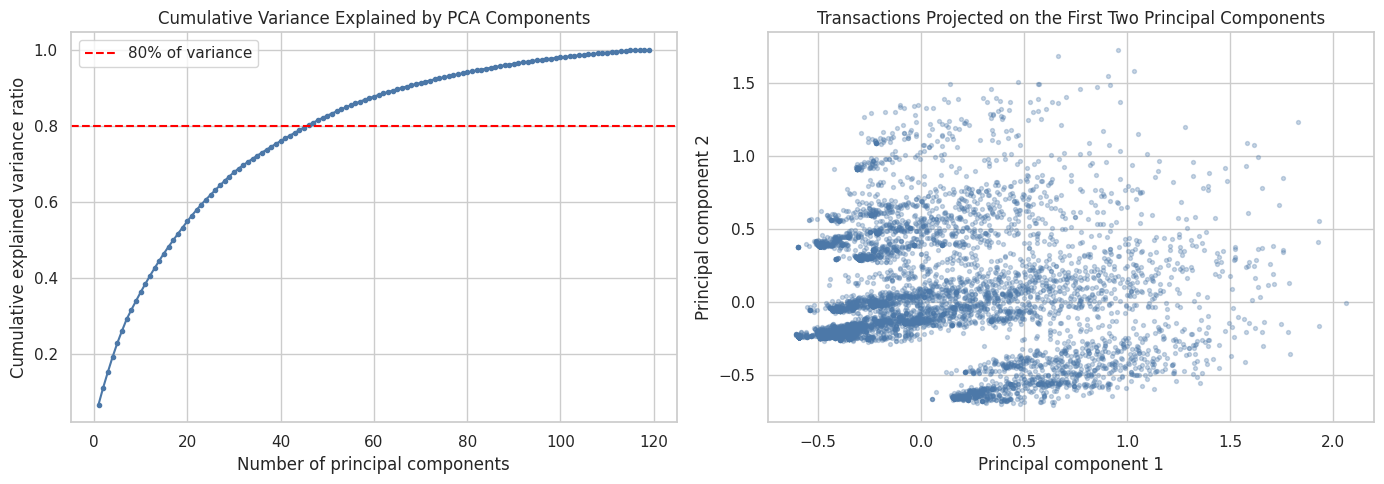

Products with the largest positive loading on PC1: ['mineral water', 'spaghetti', 'milk', 'chocolate', 'ground beef']
Products with the largest positive loading on PC2: ['french fries', 'eggs', 'chocolate', 'green tea', 'burgers']


In [7]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for target in (0.5, 0.8, 0.9):
    print(f"Components needed to explain {int(target*100)}% of the variance:", int(np.argmax(cum_var >= target) + 1))
print("Variance explained by PC1 and PC2:", pca_full.explained_variance_ratio_[:2].round(4), "| total:", round(pca_full.explained_variance_ratio_[:2].sum(), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum_var) + 1), cum_var, marker=".", color="#4c78a8")
axes[0].axhline(0.8, color="red", linestyle="--", label="80% of variance")
axes[0].set_title("Cumulative Variance Explained by PCA Components")
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Cumulative explained variance ratio")
axes[0].legend()

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.3, color="#4c78a8")
axes[1].set_title("Transactions Projected on the First Two Principal Components")
axes[1].set_xlabel("Principal component 1")
axes[1].set_ylabel("Principal component 2")
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca2.components_.T, index=X_df.columns, columns=["PC1", "PC2"])
print("Products with the largest positive loading on PC1:", list(loadings["PC1"].nlargest(5).index))
print("Products with the largest positive loading on PC2:", list(loadings["PC2"].nlargest(5).index))

**Interpretation.**
- The first two principal components explain only **11.2%** of the variance (PC1 6.7%, PC2 4.5%). About **18 components are needed for 50%** of the variance, **46 for 80%** and **66 for 90%**. The information is spread over many directions, so the 2-D picture is only a rough summary and cannot show the full cluster structure.
- PC1 is driven mainly by popular products (mineral water, spaghetti, milk, chocolate, ground beef), so it behaves roughly like a "bigger basket with common items" axis. PC2 is driven by french fries, eggs, chocolate, green tea and burgers.
- The scatter plot does **not** show clearly separated blobs. The visible diagonal streaks are an artefact of binary data (baskets with 1-2 items fall on a few discrete positions). This is already a warning sign that clusters will be weak.

## 6. Model building: clustering algorithms

### 6.1 Choosing the number of clusters for K-means
I run K-means for k = 2 to 10 and compare three criteria: **inertia** (elbow method; look for the point where improvement slows), the **silhouette coefficient** (higher is better, from -1 to 1) and the **Davies-Bouldin index** (lower is better). The silhouette score is computed on a random sample of 3,000 transactions to keep the computation fast.

,Inertia,Silhouette,Davies-Bouldin
k,,,
2,25322.099,0.125,3.496
3,24459.405,0.089,3.346
4,23731.880,0.072,3.196
5,23319.843,0.071,3.072
6,22934.256,0.064,3.513
7,22531.975,0.062,3.013
8,22174.005,0.055,3.207
9,21935.414,0.025,3.210
10,21764.511,0.025,3.279


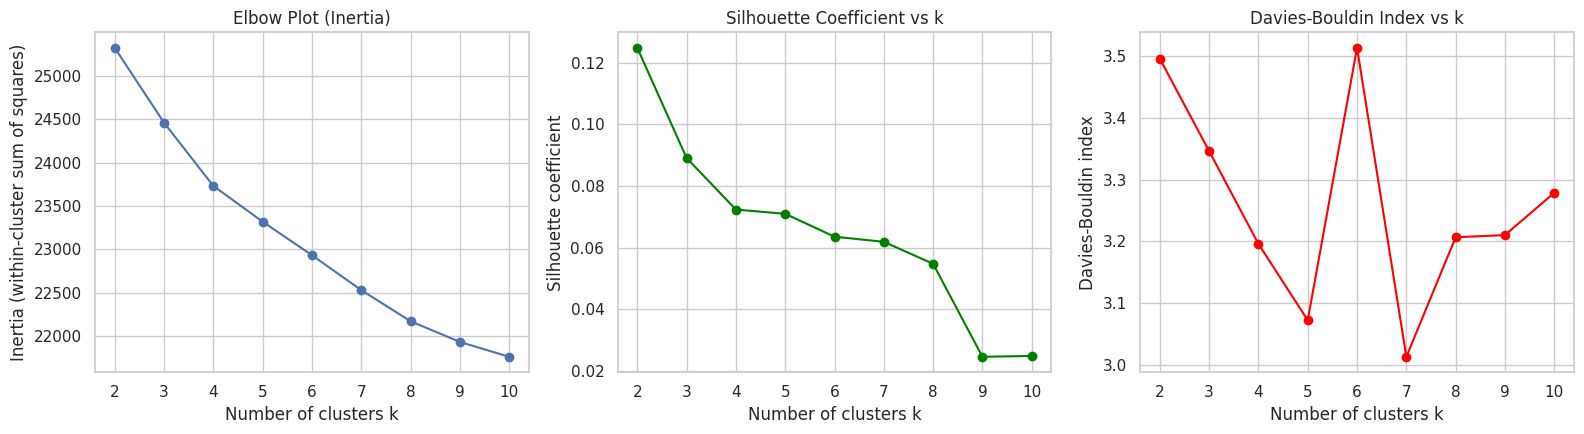

In [8]:
ks = range(2, 11)
sweep = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    sweep.append({"k": k, "Inertia": km.inertia_,
                  "Silhouette": silhouette_score(X, km.labels_, sample_size=3000, random_state=RANDOM_STATE),
                  "Davies-Bouldin": davies_bouldin_score(X, km.labels_)})
sweep = pd.DataFrame(sweep).set_index("k")
display(sweep.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(sweep.index, sweep["Inertia"], marker="o"); axes[0].set_title("Elbow Plot (Inertia)")
axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[1].plot(sweep.index, sweep["Silhouette"], marker="o", color="green"); axes[1].set_title("Silhouette Coefficient vs k")
axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Silhouette coefficient")
axes[2].plot(sweep.index, sweep["Davies-Bouldin"], marker="o", color="red"); axes[2].set_title("Davies-Bouldin Index vs k")
axes[2].set_xlabel("Number of clusters k"); axes[2].set_ylabel("Davies-Bouldin index")
plt.tight_layout()
plt.show()

**Interpretation.**
- The elbow curve falls smoothly and shows **no sharp elbow**, so inertia does not give a clear k.
- The **silhouette is highest for k = 2 (0.125)** and then declines, while the **Davies-Bouldin index** is lowest around k = 5-7 (about 3.0-3.1). The two criteria disagree.
- All silhouette values are **below 0.13**, which means that the clusters overlap strongly; the data does not contain well-separated natural groups.
- I choose **K = 3** as a compromise: its silhouette (0.089) is close to the best value, and three groups are still easy to interpret as business segments (and give the hierarchical and spectral methods a non-trivial comparison). k = 2 would only split small from large baskets. I keep this limitation in mind when interpreting the results.

In [9]:
K = 3   # chosen number of clusters, see the explanation above

### 6.2 K-means (full data)

In [10]:
t0 = time.time()
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
km_time = time.time() - t0
km_labels_full = kmeans.labels_
print("K-means cluster sizes:")
print(pd.Series(km_labels_full).value_counts().sort_index().to_string())
print("Silhouette (3000-point sample):", round(silhouette_score(X, km_labels_full, sample_size=3000, random_state=RANDOM_STATE), 4))
print("Davies-Bouldin:", round(davies_bouldin_score(X, km_labels_full), 4))

K-means cluster sizes:
0    4677
1    1178
2    1646
Silhouette (3000-point sample): 0.0891
Davies-Bouldin: 3.3461


### 6.3 Hierarchical clustering
A dendrogram of all 7,501 baskets would be unreadable and very slow, so I draw it for a random sample of 150 baskets using Ward linkage, and then fit agglomerative clustering with Ward linkage to the full data.

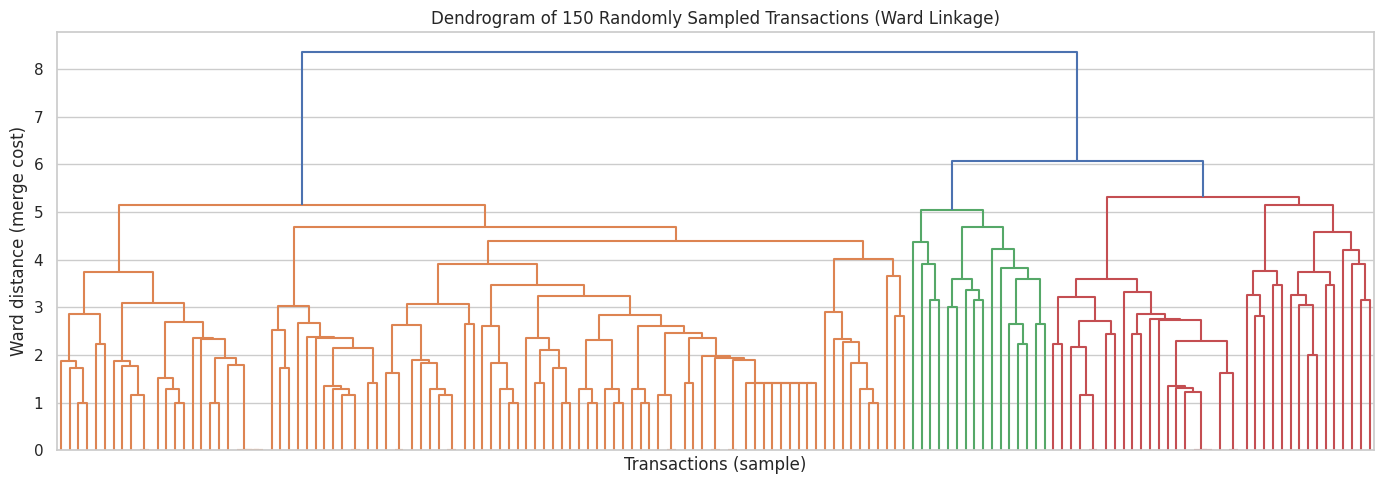

Hierarchical cluster sizes:
0    4895
1    2317
2     289
Silhouette (3000-point sample): -0.1209
Davies-Bouldin: 5.0416


In [11]:
rng = np.random.default_rng(RANDOM_STATE)
dend_idx = rng.choice(len(X), size=150, replace=False)
Z = linkage(X[dend_idx], method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True, color_threshold=0.7 * Z[:, 2].max())
plt.title("Dendrogram of 150 Randomly Sampled Transactions (Ward Linkage)")
plt.xlabel("Transactions (sample)")
plt.ylabel("Ward distance (merge cost)")
plt.tight_layout()
plt.show()

t0 = time.time()
hier_full = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
hier_time = time.time() - t0
hier_labels_full = hier_full.labels_
print("Hierarchical cluster sizes:")
print(pd.Series(hier_labels_full).value_counts().sort_index().to_string())
print("Silhouette (3000-point sample):", round(silhouette_score(X, hier_labels_full, sample_size=3000, random_state=RANDOM_STATE), 4))
print("Davies-Bouldin:", round(davies_bouldin_score(X, hier_labels_full), 4))

**Interpretation.**
- The dendrogram shows one tall final merge (height about 8.4) that splits the sample into a large group (left, orange) and a smaller one (green and red), with no large gaps below it. Merge heights rise gradually, so there is **no obviously "natural" number of clusters**, which agrees with the weak K-means scores.
- Cutting at three clusters on the full data gives sizes **4,895 / 2,317 / 289**. The silhouette is **negative (-0.12)** and the Davies-Bouldin index is high (5.04), so Ward hierarchical clustering performs clearly worse than K-means here, and it was also much slower (about 3.2 s versus 0.2 s).

### 6.4 Common evaluation sample
Spectral clustering and DBSCAN with a Jaccard distance matrix are memory-hungry for 7,501 points, so I run **all four algorithms on the same random sample of 2,000 transactions**. Using the same data and the same scoring rule is what makes the comparison fair.

In [12]:
SAMPLE_N = 2000
sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(X), size=SAMPLE_N, replace=False)
Xs = X[sample_idx]
print("Sample shape:", Xs.shape, "| mean basket size in sample:", round(Xs.sum(axis=1).mean(), 2), "(full data:", round(X.sum(axis=1).mean(), 2), ")")

Sample shape: (2000, 119) | mean basket size in sample: 3.83 (full data: 3.91 )


### 6.5 DBSCAN
DBSCAN needs a distance and two parameters: `eps` (neighbourhood radius) and `min_samples`. For binary baskets the **Jaccard distance** (1 minus the share of shared products among all products in the two baskets) is natural. I try several `eps` values with `min_samples = 5` and look at the number of clusters and the amount of noise.

In [13]:
D_jac = pairwise_distances(Xs.astype(bool), metric="jaccard")

rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    lab = DBSCAN(eps=eps, min_samples=5, metric="precomputed").fit_predict(D_jac)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    rows.append({"eps": eps, "Clusters": n_cl, "Noise points": int((lab == -1).sum()),
                 "Noise (%)": round((lab == -1).mean() * 100, 1),
                 "Largest cluster (%)": round(pd.Series(lab[lab != -1]).value_counts().max() / len(lab) * 100, 1) if n_cl else 0})
dbscan_grid = pd.DataFrame(rows).set_index("eps")
display(dbscan_grid)

,Clusters,Noise points,Noise (%),Largest cluster (%)
eps,,,,
0.3,33,1592,79.6,2.6
0.4,41,1314,65.7,10.0
0.5,1,628,31.4,68.6
0.6,2,263,13.2,86.8
0.7,1,23,1.2,98.9
0.8,1,0,0.0,100.0


**Interpretation.**
- With `eps = 0.3-0.4`, DBSCAN finds **33-41 tiny clusters** but labels **66-80% of baskets as noise**: only very tight groups of near-identical baskets qualify.
- At `eps = 0.5` the clusters suddenly merge into **one** big cluster (68.6% of baskets), and at `eps >= 0.7` essentially everything is one cluster. There is **no setting in between** that gives a few meaningful, balanced clusters, because baskets are so sparse that their Jaccard distances are mostly either very small (near-identical) or very large.
- I use **eps = 0.6** as the main setting (13% noise, but practically one dense cluster plus a 2-point cluster) and keep **eps = 0.4** as the "many small clusters" alternative so that both behaviours are compared fairly below.

In [14]:
DB_EPS = 0.6        # main value, see explanation above
DB_EPS_ALT = 0.4    # second value with many small clusters, kept for comparison
t0 = time.time()
db_labels_s = DBSCAN(eps=DB_EPS, min_samples=5, metric="precomputed").fit_predict(D_jac)
db_time = time.time() - t0
db_labels_alt = DBSCAN(eps=DB_EPS_ALT, min_samples=5, metric="precomputed").fit_predict(D_jac)
for e, lab in [(DB_EPS, db_labels_s), (DB_EPS_ALT, db_labels_alt)]:
    sizes = pd.Series(lab[lab != -1]).value_counts()
    print(f"DBSCAN eps={e}: clusters={len(sizes)}, noise={int((lab == -1).sum())} ({(lab == -1).mean()*100:.1f}%), "
          f"largest cluster={sizes.iloc[0]}, smallest cluster={sizes.iloc[-1]}")

DBSCAN eps=0.6: clusters=2, noise=263 (13.2%), largest cluster=1735, smallest cluster=2
DBSCAN eps=0.4: clusters=41, noise=1314 (65.7%), largest cluster=201, smallest cluster=4


### 6.6 Spectral clustering
Spectral clustering builds a nearest-neighbour graph of baskets and clusters its eigenvectors. I use 10 nearest neighbours and the same K as K-means.

In [15]:
t0 = time.time()
spec = SpectralClustering(n_clusters=K, affinity="nearest_neighbors", n_neighbors=10,
                          assign_labels="kmeans", random_state=RANDOM_STATE)
spec_labels_s = spec.fit_predict(Xs)
spec_time = time.time() - t0
print("Spectral cluster sizes:")
print(pd.Series(spec_labels_s).value_counts().sort_index().to_string())

Spectral cluster sizes:
0      13
1    1867
2     120


## 7. Model evaluation: comparing the algorithms (Objective 8)
On the common 2,000-transaction sample I score every algorithm with the **same metrics, computed in the same Euclidean feature space**. DBSCAN labels some points as noise, so I report it **two ways**: (a) scoring only the points DBSCAN assigned to clusters (which flatters it, because the hardest points are removed), and (b) treating all noise points as one extra "noise" group, which penalises it fairly. The share of points actually clustered is reported as *coverage*.

,Clusters,Coverage (%),Silhouette,Davies-Bouldin
Algorithm,,,,
K-means,3,100.00,0.0994,3.2250
Hierarchical (Ward),3,100.00,0.0108,4.9153
Spectral,3,100.00,-0.1291,2.3401
DBSCAN eps=0.6 (noise excluded),2,86.85,0.1737,1.2659
DBSCAN eps=0.6 (noise = own group),3,100.00,0.1298,6.2919
DBSCAN eps=0.4 (noise excluded),41,34.30,0.4482,1.3505
DBSCAN eps=0.4 (noise = own group),42,100.00,-0.0818,2.1234


,Silhouette,Davies-Bouldin,Run time (s)
K-means (full data),0.0891,3.3461,0.2020
Hierarchical (full data),-0.1209,5.0416,3.4711


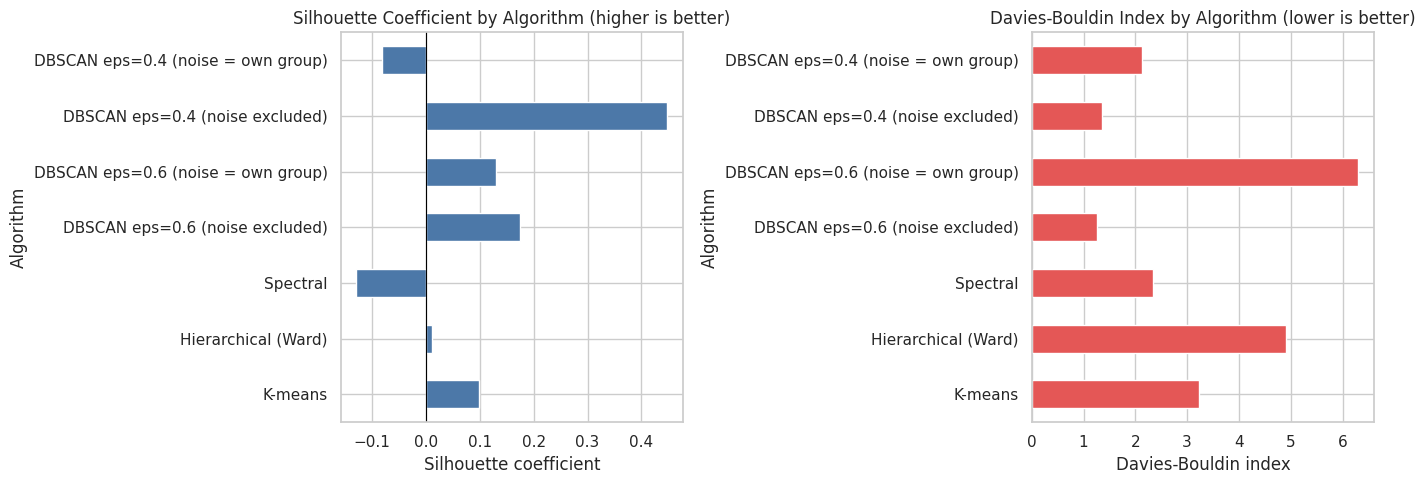

In [16]:
def score(Xm, labels):
    return silhouette_score(Xm, labels), davies_bouldin_score(Xm, labels)

# K-means and hierarchical re-fitted on the same sample
t0 = time.time(); km_s = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs); t_km = time.time() - t0
t0 = time.time(); hc_s = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Xs); t_hc = time.time() - t0

rows = []
for name, lab, t in [("K-means", km_s, t_km), ("Hierarchical (Ward)", hc_s, t_hc), ("Spectral", spec_labels_s, spec_time)]:
    s, d = score(Xs, lab)
    rows.append({"Algorithm": name, "Clusters": len(set(lab)), "Coverage (%)": 100.0, "Silhouette": s, "Davies-Bouldin": d})

for eps, lab in [(DB_EPS, db_labels_s), (DB_EPS_ALT, db_labels_alt)]:
    mask = lab != -1
    s, d = score(Xs[mask], lab[mask])
    rows.append({"Algorithm": f"DBSCAN eps={eps} (noise excluded)", "Clusters": len(set(lab[mask])), "Coverage (%)": mask.mean() * 100, "Silhouette": s, "Davies-Bouldin": d})
    s, d = score(Xs, lab)
    rows.append({"Algorithm": f"DBSCAN eps={eps} (noise = own group)", "Clusters": len(set(lab)), "Coverage (%)": 100.0, "Silhouette": s, "Davies-Bouldin": d})

comparison = pd.DataFrame(rows).set_index("Algorithm")
display(comparison.round(4))

# Supplementary: K-means and hierarchical on the FULL data (3,000-point sample for silhouette)
full_tbl = pd.DataFrame({
    "Silhouette": [silhouette_score(X, km_labels_full, sample_size=3000, random_state=RANDOM_STATE),
                   silhouette_score(X, hier_labels_full, sample_size=3000, random_state=RANDOM_STATE)],
    "Davies-Bouldin": [davies_bouldin_score(X, km_labels_full), davies_bouldin_score(X, hier_labels_full)],
    "Run time (s)": [km_time, hier_time]}, index=["K-means (full data)", "Hierarchical (full data)"])
display(full_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
comparison["Silhouette"].plot(kind="barh", ax=axes[0], color="#4c78a8")
axes[0].set_title("Silhouette Coefficient by Algorithm (higher is better)")
axes[0].set_xlabel("Silhouette coefficient")
axes[0].set_ylabel("Algorithm")
axes[0].axvline(0, color="black", linewidth=0.8)
comparison["Davies-Bouldin"].plot(kind="barh", ax=axes[1], color="#e45756")
axes[1].set_title("Davies-Bouldin Index by Algorithm (lower is better)")
axes[1].set_xlabel("Davies-Bouldin index")
axes[1].set_ylabel("Algorithm")
plt.tight_layout()
plt.show()

**Interpretation.**
- **K-means** is the best of the algorithms that assign every basket to a cluster: silhouette about **0.10** and Davies-Bouldin **3.2** on the sample (0.089 and 3.35 on the full data). It is also by far the fastest. A silhouette this close to zero still means the clusters overlap heavily.
- **Hierarchical (Ward)** is much worse (silhouette about 0.01, Davies-Bouldin 4.9, 3.2 s run time on the full data).
- **Spectral clustering** has a negative silhouette (**-0.13**). Its Davies-Bouldin value of 2.34 looks good but is **misleading**: the clusters have 13, 1,867 and 120 baskets, i.e. one giant cluster plus two tiny ones, and the index rewards that.
- **DBSCAN** has the best-looking numbers when noise is removed (silhouette 0.17-0.45, Davies-Bouldin 1.3), but this is because the hardest points are thrown away: at eps = 0.4 only **34%** of baskets are clustered at all, and at eps = 0.6 the "two clusters" are one big cluster and a 2-point cluster. When the noise points are counted as their own group (the fair treatment), the scores drop to 0.13 / 6.29 (eps 0.6) and -0.08 / 2.12 (eps 0.4).
- **Conclusion on performance:** no algorithm finds strong cluster structure. **K-means gives the most usable segmentation** (every basket assigned, balanced and interpretable groups, fast). DBSCAN is useful for a different purpose: spotting very tight groups of almost identical baskets.

### Visual comparison on the PCA plane

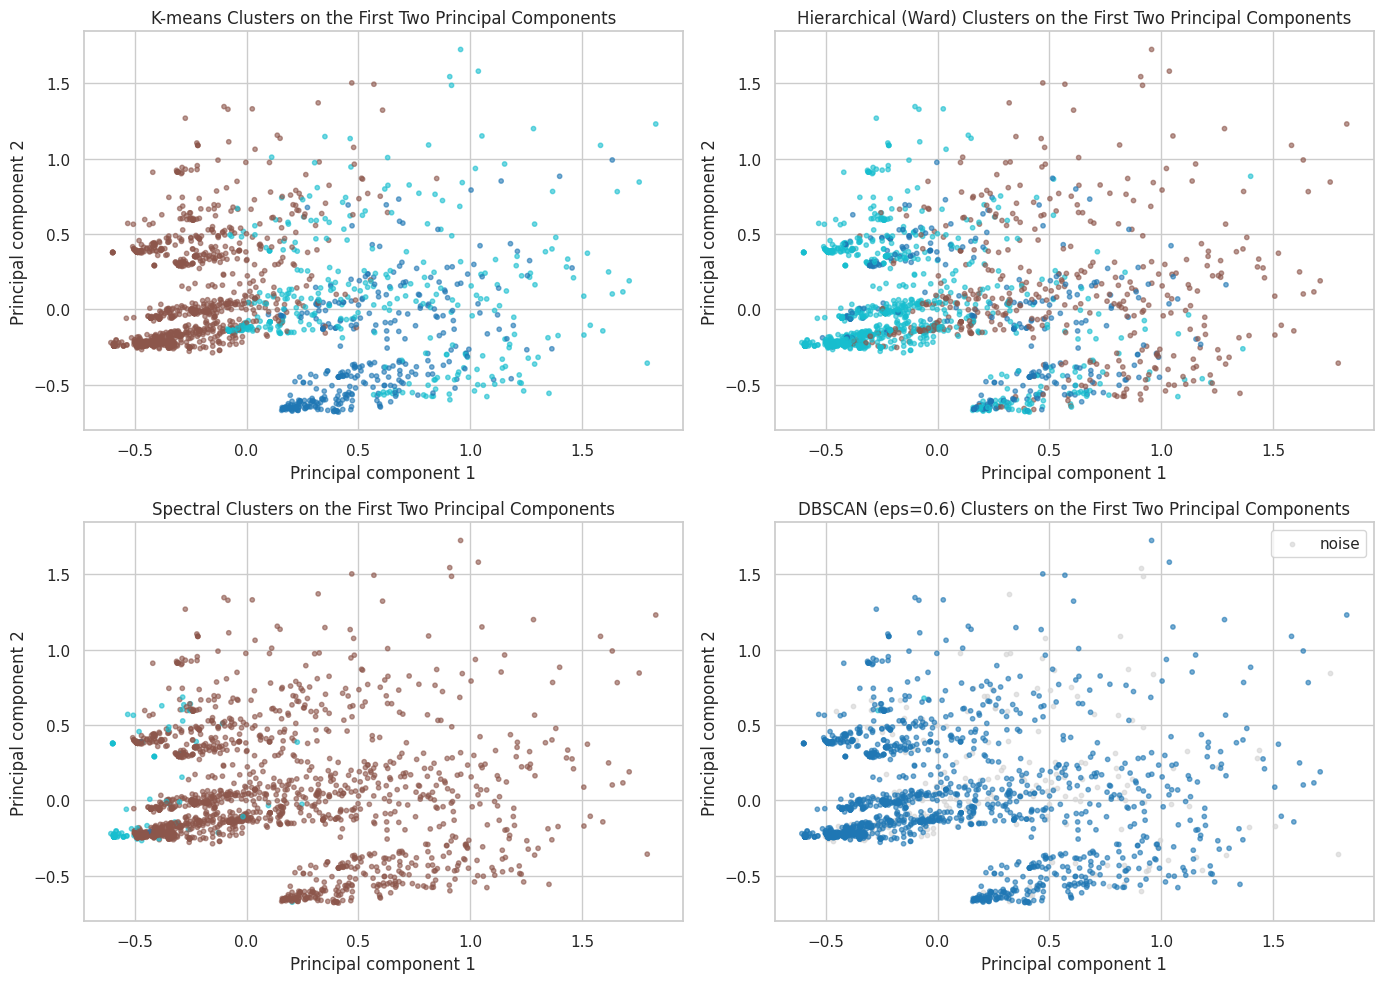

In [17]:
Xs_pca = pca2.transform(Xs)   # PCA fitted on the full data, applied to the sample
panels = [("K-means", km_s), ("Hierarchical (Ward)", hc_s), ("Spectral", spec_labels_s), (f"DBSCAN (eps={DB_EPS})", db_labels_s)]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (name, lab) in zip(axes.ravel(), panels):
    noise = lab == -1
    if noise.any():   # DBSCAN: draw noise points in grey so they are not confused with a cluster
        ax.scatter(Xs_pca[noise, 0], Xs_pca[noise, 1], c="lightgrey", s=10, alpha=0.6, label="noise")
        ax.legend(loc="upper right")
    ax.scatter(Xs_pca[~noise, 0], Xs_pca[~noise, 1], c=lab[~noise], cmap="tab10", s=10, alpha=0.6)
    ax.set_title(f"{name} Clusters on the First Two Principal Components")
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
plt.tight_layout()
plt.show()

**Interpretation of the PCA plots.**
- **K-means** splits the cloud mainly along PC1 (large baskets with popular products on the right, small baskets on the left), which is a sensible and visible separation, although the groups touch.
- **Hierarchical** clusters are interleaved with each other, matching its poor scores.
- **Spectral** puts almost every point into one cluster, with a tiny cluster in the lower-left corner, so it effectively fails to segment the data.
- **DBSCAN** (grey points are noise) finds one dense core cluster with noise scattered all over the cloud, so it does not produce distinct segments either.

## 8. Cluster profiling and business interpretation

,Baskets,Share (%),Avg basket size,Most frequent products,Highest-lift products (support >= 5%)
Cluster,,,,,
0,4677,62.4,3.05,"eggs, spaghetti, chocolate, green tea, milk, cookies","cookies, champagne, escalope, green tea, turkey"
1,1178,15.7,4.72,"french fries, eggs, chocolate, green tea, mineral water, burgers","french fries, burgers, frozen smoothie, green tea, escalope"
2,1646,21.9,5.79,"mineral water, spaghetti, chocolate, eggs, milk, ground beef","mineral water, soup, ground beef, olive oil, salmon"


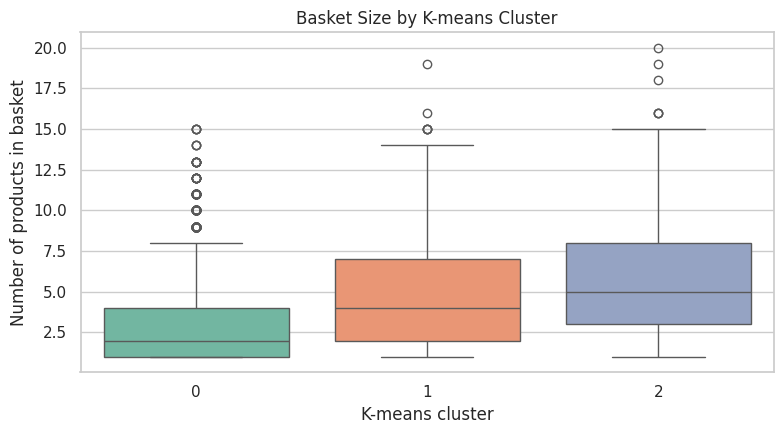

In [18]:
labels = km_labels_full
profile_rows = []
overall = X.mean(axis=0)
for c in range(K):
    m = labels == c
    share = X[m].mean(axis=0)
    lift = share / overall
    top_freq = [p for p in pd.Series(share, index=X_df.columns).nlargest(6).index]
    top_lift = [p for p in pd.Series(lift, index=X_df.columns)[pd.Series(share, index=X_df.columns) >= 0.05].nlargest(5).index]
    profile_rows.append({"Cluster": c, "Baskets": int(m.sum()), "Share (%)": round(m.mean() * 100, 1),
                         "Avg basket size": round(basket_sizes.values[m].mean(), 2),
                         "Most frequent products": ", ".join(top_freq),
                         "Highest-lift products (support >= 5%)": ", ".join(top_lift)})
profile = pd.DataFrame(profile_rows).set_index("Cluster")
pd.set_option("display.max_colwidth", 200)
display(profile)

plt.figure(figsize=(8, 4.5))
sns.boxplot(x=pd.Series(labels, name="Cluster"), y=basket_sizes.values, palette="Set2")
plt.title("Basket Size by K-means Cluster")
plt.xlabel("K-means cluster")
plt.ylabel("Number of products in basket")
plt.tight_layout()
plt.show()

**Interpretation of the K-means segments.**
- **Cluster 0 (62% of baskets, 3.05 items on average): "small everyday baskets".** Typical items are eggs, spaghetti, chocolate, green tea, milk and cookies. Over-represented items (lift) include cookies, champagne, escalope and turkey.
- **Cluster 1 (16% of baskets, 4.72 items): "fast-food / snack baskets".** French fries, burgers and frozen smoothies are strongly over-represented, together with green tea and eggs.
- **Cluster 2 (22% of baskets, 5.79 items): "large home-cooking / healthy stock-up baskets".** Mineral water, soup, ground beef, olive oil and salmon stand out.
- The box plot confirms that the clusters differ clearly in **basket size**; the segmentation therefore reflects both *how much* customers buy and *what kind* of products they buy. Because the silhouette is low, these are tendencies, not sharply separated groups.

## 9. Limitations and business implications (Objective 9)

**Limitations**
1. **Weak cluster structure.** All silhouette scores are low (at most about 0.13 for complete partitions), so the baskets do not form natural groups; the segments describe tendencies, not distinct customer types.
2. **Binary representation.** One-hot encoding ignores quantities, prices, product categories and the order of purchase. Also, sparse binary vectors make Euclidean distance poorly suited; most baskets share no products.
3. **Sampling.** Spectral clustering and the DBSCAN Jaccard matrix were run on a random sample of 2,000 baskets (about 27% of the data) because of memory and time limits. Results on the full data could differ.
4. **Parameter sensitivity.** Results depend on K, `eps`, `min_samples` and `n_neighbors`. I tried several values for K and `eps` but not an exhaustive grid.
5. **Metric limitations.** The silhouette and Davies-Bouldin indices assume compact, roughly spherical clusters, so they are not ideal for density-based methods such as DBSCAN, and Davies-Bouldin can reward degenerate clusterings (as with spectral clustering here).
6. **Missing information.** There is no customer ID, date, price or quantity, so we cannot study repeat customers, seasonality or revenue.

**Business implications**
- **Bundling and promotions:** pair products that are bought together in the segments, for example french fries with burgers, or mineral water with ground beef and olive oil.
- **Store layout and recommendations:** place high-lift products near each other and recommend them on the product page of the segment's anchor items.
- **Basket-size strategy:** about 62% of baskets are small (average about 3 items), so offers that encourage adding one more item (a "complete your meal" suggestion) could raise basket size, the biggest differentiator between the clusters.
- **Next steps:** association-rule mining (support, confidence, lift) is probably better suited than clustering for finding product relationships, and adding price, customer and time data would allow real customer segmentation.

## 10. Conclusion

The store's 7,501 baskets are small (mean 3.9 items, right-skewed) and dominated by a few staples such as mineral water, eggs, spaghetti, french fries and chocolate, with a long tail of rarely bought products. After encoding each basket as a 119-dimensional binary vector, PCA showed that two components capture only 11% of the variance, and none of the clustering methods found strongly separated groups. K-means (K = 3) gave the best usable result, with a silhouette of about 0.09-0.10 and a Davies-Bouldin index of about 3.2-3.3: three interpretable segments (small everyday baskets, fast-food/snack baskets and large home-cooking/healthy baskets) that differ mainly in basket size and product mix. Hierarchical clustering and spectral clustering performed worse (the latter produced a degenerate partition), and DBSCAN's apparently better scores came from discarding most of the hard points as noise. The practical conclusion is that the data supports broad segments and product-bundling ideas, but not sharply defined customer clusters, and richer data (quantities, prices, customers, time) and association-rule mining would be natural next steps.

## References
- scikit-learn documentation: KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering, PCA, silhouette_score, davies_bouldin_score.
- SciPy documentation: hierarchical clustering and dendrograms.
